# Mechanisms in BrainCell

This notebook now stays intentionally narrow.

`Ion` and `Channel` already have dedicated walkthroughs in `6.channel.ipynb` and `7.ion.ipynb`. Here we only keep the minimum density background needed to make point mechanisms concrete, then spend most of the notebook on **recordings**, which read runtime state and current back out of a cell.

At the declaration layer, the current multi-compartment mechanism surface still splits into two families:

- `Density`: installed with `cell.paint(region, ...)`
- `Point`: installed with `cell.place(locset, ...)`

`CableProperty` is closely related, but it is a passive cable declaration rather than a `Mechanism` subclass. A recording is not a mechanism at all: it is declared on the cell with `record(...)` and adds nothing to the model.

| Family | Declaration | Attach with | What matters most | Coverage here |
| --- | --- | --- | --- | --- |
| Passive cable declaration | `CableProperty` | `cell.paint(region, ...)` | Passive defaults such as `v_rest`, `cm`, `ra`, `temperature` | Short reminder |
| Density mech | `Ion` | `cell.paint(region, ...)` | Runtime ion containers and ion-side state | See `7.ion.ipynb` |
| Density mech | `Channel` | `cell.paint(region, ...)` | Distributed conductance mechanisms bound to ions | See `6.channel.ipynb` |
| Point mech | `CurrentClamp` / `SineClamp` / `FunctionClamp` | `cell.place(locset, ...)` | Current injection at point locations | Short refresher |
| Point mech | `Synapse` / `Junction` | `cell.place(locset, ...)` | Synaptic and gap-junction workflows | Overview only |
| Recording | `braincell.observe.*` | `cell.record(...)` / `cell.loc(locset).record(...)` | Read runtime state and current back out of the cell | Main focus |

The point probes of earlier releases were removed in braincell 0.3; recordings replace them.

In [1]:
import os

os.environ.setdefault("JAX_PLATFORMS", "cpu")
os.environ.setdefault("MPLBACKEND", "Agg")

import brainunit as u
import matplotlib.pyplot as plt

import braincell
from braincell import Branch, Cell, Morphology
from braincell.filter import AllRegion, BranchSlice, RootLocation, Terminals, at
from braincell.mech import (
    CableProperty,
    Channel,
    CurrentClamp,
    FunctionClamp,
    Ion,
    SineClamp,
)


def build_demo_morphology() -> Morphology:
    soma = Branch.from_lengths(
        lengths=[20.0] * u.um,
        radii=[8.0, 8.0] * u.um,
        type="soma",
    )
    dend = Branch.from_lengths(
        lengths=[60.0] * u.um,
        radii=[2.0, 1.2] * u.um,
        type="basal_dendrite",
    )
    axon = Branch.from_lengths(
        lengths=[80.0] * u.um,
        radii=[1.0, 0.6] * u.um,
        type="axon",
    )
    morpho = Morphology.from_root(soma, name="soma")
    morpho.attach(parent="soma", child_branch=dend, child_name="dend", parent_x=1.0)
    morpho.attach(parent="soma", child_branch=axon, child_name="axon", parent_x=0.0)
    return morpho


## 1. Density declarations: only the minimum background

The density side has three layers:

1. `CableProperty` sets passive cable defaults.
2. `Ion` declares ion containers and any ion-side runtime state.
3. `Channel` installs distributed mechanisms that bind to those ions.

For the full density story, use the neighboring notebooks instead of this one:

- `4.cell.ipynb` for the paint/place workflow on `Cell`
- `6.channel.ipynb` for channel templates, gates, and generated ODEs
- `7.ion.ipynb` for ion templates, Nernst handling, and dynamic ion state

That is enough context for recordings, because a recording reads the runtime state that `Cell.init_state()` materializes from these declarations.


### 1.1 `CableProperty`: paintable, central, but passive

`CableProperty` uses the same `paint(...)` entry point as density mechanisms, so it still belongs in the mental model even though it does not inherit from `Mechanism`.


In [2]:
morpho = build_demo_morphology()
print(morpho.topo())

cell_passive = Cell(morpho)
cell_passive.paint(
    AllRegion(),
    CableProperty(
        resting_potential=-65.0 * u.mV,
        membrane_capacitance=1.0 * (u.uF / u.cm**2),
        axial_resistivity=100.0 * (u.ohm * u.cm),
    ),
)

print()
print(cell_passive)
print("root CV resting potential:", cell_passive.cvs[0].v)


soma
├── dend
└── axon

Cell(root='soma', n_branches=3, n_paint_rules=1, n_place_rules=0, initialized=False)
root CV resting potential: -65. mV


## 2. Point mechanisms: stimuli and synapses

Point mechanisms live at one location in the point tree rather than across a branch interval. Locsets decide **where** they land. If you want the full locset vocabulary, see `2.filter.ipynb`.

Point mechanisms add something to the model: a current injection, a synapse, a junction. Reading values back out is not a point mechanism; section 3 declares recordings for that.

### 2.1 Clamp declarations: a quick refresher

`CurrentClamp`, `SineClamp`, and `FunctionClamp` all feed the same runtime path: `cell.runtime.evaluate_point_clamps(t=...)`.

If several clamps are placed at the same point, their currents add. Since the rest of this notebook is about recordings, we only keep one short runnable refresher here.


In [3]:
cell_clamp = Cell(build_demo_morphology())
cell_clamp.place(
    RootLocation(x=0.5),
    CurrentClamp(
        delay=0.0 * u.ms,
        durations=(2.0 * u.ms, 2.0 * u.ms),
        amplitudes=(0.0 * u.nA, 0.3 * u.nA),
    ),
    SineClamp(
        amplitude=0.2 * u.nA,
        frequency=500.0 * u.Hz,
        offset=0.1 * u.nA,
        duration=4.0 * u.ms,
    ),
    FunctionClamp(
        fn=lambda t: 0.4 * u.nA if t < 1.0 * u.ms else 0.0 * u.nA,
    ),
)
cell_clamp.init_state()

point_index = int(cell_clamp.layouts[0].point_index[0])
current_early = cell_clamp.runtime.evaluate_point_clamps(t=0.5 * u.ms)
current_late = cell_clamp.runtime.evaluate_point_clamps(t=2.5 * u.ms)

print("layout kinds:", [layout.kind for layout in cell_clamp.layouts])
print("active point index:", point_index)
print(f"combined clamp current at 0.5 ms: {float(current_early[point_index].to_decimal(u.nA)):.3f} nA")
print(f"combined clamp current at 2.5 ms: {float(current_late[point_index].to_decimal(u.nA)):.3f} nA")


layout kinds: ['CurrentClamp', 'SineClamp', 'FunctionClamp']
active point index: 1
combined clamp current at 0.5 ms: 0.700 nA
combined clamp current at 2.5 ms: 0.600 nA


### 2.2 Other point declarations

Two public point declarations are worth knowing even though this notebook does not build their full workflows.

- `Synapse(synapse_type="ExpSyn", ...)` is the registry-keyed synapse declaration surface.
- `Junction(...)` is the current placeholder for gap-junction-style point declarations.

## 3. Recordings: reading the cell back out

A recording is a declaration on the cell, like `paint(...)` and `place(...)`, but it adds no mechanism and no state: it names values that already exist in the initialized runtime and asks `cell.run(...)` to sample them.

Every recording has two parts:

- a **scope**, the object you call `record(...)` on: `cell.record(...)` covers the whole cell, and `cell.loc(locset).record(...)` the CVs that hold the locset's points (`cell.on(region)` and `cell.soma` are other scopes);
- an **observable** from `braincell.observe`:

| Observable | Reads |
| --- | --- |
| `observe.state("V")` | the membrane voltage; `record(name, "V")` is shorthand |
| `observe.channel(name=...).state(field)` / `.current()` | a channel state field, such as a gate / the channel current |
| `observe.ion(name=...).state(field)` / `.current()` | an ion state field, such as `Ci` / the total current of that ion owner |
| `observe.synapse(name=...).state(field)` / `.current()` | a synapse state field, such as `g` / the synapse current |

`result = cell.run(dt=..., duration=...)` returns each recording under its name: `result.traces[name]` has shape `(n_steps, n_rows)`, and `result.samples[name]` adds the sample times (`.time`) and one schema row per column (`.schema.rows`).

Recordings sample **before** each step: row `k` is the state at `result.time[k]`, so row 0 is the initialized state. A run of a single step is therefore a snapshot of the state that initialization produced.

Recordings are declared before the cell is initialized. For the full vocabulary (selection by `type`, `name` or `species`, current reductions, sampling periods, recordings in a network), see the recording example, `examples/cell/recording.ipynb`.

### 3.1 A snapshot: voltage, a gate, a concentration, and currents

The cell below records six values at the soma midpoint, then runs a single step, so each recording holds one sample: the initialized state at `t = 0`.

In [4]:
cell_rec = Cell(build_demo_morphology())
region = BranchSlice(branch_index=[0, 1], prox=0.0, dist=1.0)

cell_rec.paint(
    region,
    Channel("IL", g_max=0.03 * (u.mS / u.cm**2), E=-54.387 * u.mV),
    Channel("Na_HH1952", g_max=120.0 * (u.mS / u.cm**2)),
    Ion("SodiumFixed", name="na"),
    Ion(
        "CalciumDetailed",
        name="ca_dyn",
        d=0.5 * u.um,
        tau=10.0 * u.ms,
        C_rest=5.0e-5 * u.mM,
        Ci_initializer=2.4e-4 * u.mM,
    ),
)
cell_rec.paint(
    BranchSlice(branch_index=0, prox=0.0, dist=1.0),
    Channel("CaT_HM1992", ion_name="ca_dyn", g_max=2.0 * (u.mS / u.cm**2)),
)

soma = cell_rec.loc(at("soma", 0.5))
soma.record("v", braincell.observe.state("V"))
soma.record("na_p", braincell.observe.channel(name="Na_HH1952").state("p"))
soma.record("ca_ci", braincell.observe.ion(name="ca_dyn").state("Ci"))
soma.record("na_channel_current", braincell.observe.channel(name="Na_HH1952").current())
soma.record("na_ion_current", braincell.observe.ion(name="na").current())
soma.record("il_current", braincell.observe.channel(name="IL").current())

snapshot = cell_rec.run(dt=0.05 * u.ms, duration=0.05 * u.ms)
current_unit = u.mA / u.cm**2

print("recordings:", tuple(cell_rec.recordings))
print("trace shape (n_steps, n_rows):", snapshot.traces["v"].shape)
print("sample time:", snapshot.samples["v"].time)
print("v (mV):", float(snapshot.traces["v"][0, 0].to_decimal(u.mV)))
print("Na_HH1952 p:", float(snapshot.traces["na_p"][0, 0]))
print("ca_dyn Ci (mM):", float(snapshot.traces["ca_ci"][0, 0].to_decimal(u.mM)))
print(
    "Na_HH1952 channel current (mA / cm^2):",
    float(snapshot.traces["na_channel_current"][0, 0].to_decimal(current_unit)),
)
print(
    "na ion total current (mA / cm^2):",
    float(snapshot.traces["na_ion_current"][0, 0].to_decimal(current_unit)),
)
print(
    "IL channel current (mA / cm^2):",
    float(snapshot.traces["il_current"][0, 0].to_decimal(current_unit)),
)

recordings: ('v', 'na_p', 'ca_ci', 'na_channel_current', 'na_ion_current', 'il_current')
trace shape (n_steps, n_rows): (1, 1)
sample time: [0.] ms
v (mV): -65.0
Na_HH1952 p: 0.052932482212781906
ca_dyn Ci (mM): 0.00023999999393709004
Na_HH1952 channel current (mA / cm^2): 0.0012200570199638605
na ion total current (mA / cm^2): 0.0012200570199638605
IL channel current (mA / cm^2): 0.00031838996801525354


### 3.2 What can a recording measure, exactly?

The practical rules are:

- `observe.state("V")` reads the cell-owned membrane voltage, named `V` as in `cell.V`. It is the only cell state field.
- `observe.channel(name="Na_HH1952").state("p")` reads a channel gate variable or other runtime state of that channel. A `Channel` declared without `name=...` is named after its type.
- `observe.ion(name="ca_dyn").state("Ci")` reads ion state, here the dynamic calcium concentration created by `Ion("CalciumDetailed", name="ca_dyn", ...)`.
- `observe.ion(...)` selects only ions painted with `Ion(...)`. A channel whose ion is never painted runs on a default placeholder ion, which no ion recording selects (it gives zero rows). That is why the cell above paints `Ion("SodiumFixed", name="na")`, the default sodium ion, explicitly.
- `.current()` on a channel reads that channel's current; on an ion, it reads the **total** current of that ion owner.

In the snapshot above, the `Na_HH1952` channel current and the `na` ion total match because only one sodium channel writes to that ion. Once several sodium channels share the same ion owner, the ion total becomes their sum.

Recording names are yours: they key `result.traces` and `result.samples`, and a cell rejects a second recording with the same name.

### 3.3 One locset, several rows

A locset that resolves to several points gives one recording with several rows.

In [5]:
morpho_multi = build_demo_morphology()
locset = RootLocation(x=0.5) | Terminals()

cell_multi = Cell(morpho_multi)
cell_multi.loc(locset).record("v", braincell.observe.state("V"))
v_block = cell_multi.run(dt=0.05 * u.ms, duration=0.05 * u.ms).samples["v"]

print("locset display names:", morpho_multi.select(locset).display_names)
print("trace shape (n_steps, n_rows):", v_block.values.shape)
print()
for row in v_block.schema.rows:
    print(f"row: cell {row.population_index}, CV {row.cv_id}, branch {row.branch_id}, field {row.field}")
print()
print("layouts added by the recording:", [layout.kind for layout in cell_multi.layouts])

locset display names: ('soma(0.5)', 'dend(1)', 'axon(1)')
trace shape (n_steps, n_rows): (1, 3)

row: cell 0, CV 0, branch 0, field V
row: cell 0, CV 1, branch 1, field V
row: cell 0, CV 2, branch 2, field V

layouts added by the recording: []


The recording holds one row per CV that contains a selected point (two points in the same CV share one row), and `schema.rows` says which population member, CV and branch each column belongs to. The recording adds no layout: the cell runs exactly as it would without it.

### 3.4 Currents on mixed-ion channels: owner versus modulators

Mixed-ion channels need one more piece of vocabulary.

`Kca3p1_MA2020_GoC` uses potassium as the **current owner**, while calcium acts as a **modulator** of the gating dynamics. In that case:

- `observe.channel(name="Kca3p1_MA2020_GoC").current()` asks the mechanism itself for its current, using all ions that were bound to it at runtime.
- `observe.ion(name="k_main").current()` asks the potassium owner for its **total** current, which may include several potassium channels.

To make that distinction visible, the example below adds a second potassium channel and briefly depolarizes the soma before comparing the two recorded currents.

In [6]:
cell_mixed = Cell(build_demo_morphology())
region = BranchSlice(branch_index=[0, 1], prox=0.0, dist=1.0)

cell_mixed.paint(
    region,
    Ion("PotassiumFixed", name="k_main", E=-88.0 * u.mV),
    Ion("CalciumFixed", name="ca_hva", Ci=2e-4 * u.mM),
    Ion("CalciumFixed", name="ca_lva", Ci=5e-4 * u.mM),
)
cell_mixed.paint(
    region,
    Channel("Kca3p1_MA2020_GoC", ion_names={"ca": "ca_hva"}),
    Channel("K_Kv_test", ion_name="k_main", g_max=1.0 * (u.mS / u.cm**2)),
)
cell_mixed.place(
    RootLocation(x=0.5),
    CurrentClamp(delay=0.5 * u.ms, durations=10.0 * u.ms, amplitudes=0.5 * u.nA),
)
soma = cell_mixed.loc(at("soma", 0.5))
soma.record("kca_current", braincell.observe.channel(name="Kca3p1_MA2020_GoC").current())
soma.record("k_main_current", braincell.observe.ion(name="k_main").current())

result = cell_mixed.run(dt=0.05 * u.ms, duration=11.0 * u.ms)
layout = next(layout for layout in cell_mixed.layouts if layout.kind == "channel:Kca3p1_MA2020_GoC")
mech_trace = result.traces["kca_current"][:, 0].to_decimal(u.mA / u.cm**2)
total_trace = result.traces["k_main_current"][:, 0].to_decimal(u.mA / u.cm**2)

print(sorted(result.traces))
print("bound ion keys:", cell_mixed.runtime.bound_ion_keys[layout.id])
print("current owner:", cell_mixed.runtime.current_owner_keys[layout.id])
print(f"last sample time: {float(result.samples['kca_current'].time[-1].to_decimal(u.ms)):.2f} ms")
print("last Kca mechanism current (mA / cm^2):", float(mech_trace[-1]))
print("last k_main total current (mA / cm^2):", float(total_trace[-1]))
print("difference at the last sample (mA / cm^2):", float(total_trace[-1] - mech_trace[-1]))

['k_main_current', 'kca_current']
bound ion keys: ('k_main', 'ca_hva')
current owner: k_main
last sample time: 10.95 ms
last Kca mechanism current (mA / cm^2): -0.027963321655988693
last k_main total current (mA / cm^2): -0.028178326785564423
difference at the last sample (mA / cm^2): -0.00021500512957572937


### 3.5 Time series from `cell.run(...)`

The snapshots above were single-step runs. For a time series, you declare the same recordings and run longer.

A few operational details matter:

- `cell.run(...)` auto-calls `init_state()` if the cell is still in DECLARING, so recordings must be declared before the first run.
- The return value is a `RunResult`: `result.time` holds the start time of every step, and `result.traces` and `result.samples` are keyed by recording name.
- Because recordings sample before each step, row `k` belongs to `result.time[k]`. Plot each trace against `result.samples[name].time`, which equals `result.time` for a recording that samples every step.

Below we drive the soma with a step current and record three traces from the same point: membrane voltage, one sodium gate variable, and the sodium channel current.

trace keys: ['na_current', 'na_p', 'v']
n timesteps: 240
current time after run (ms): 12.0


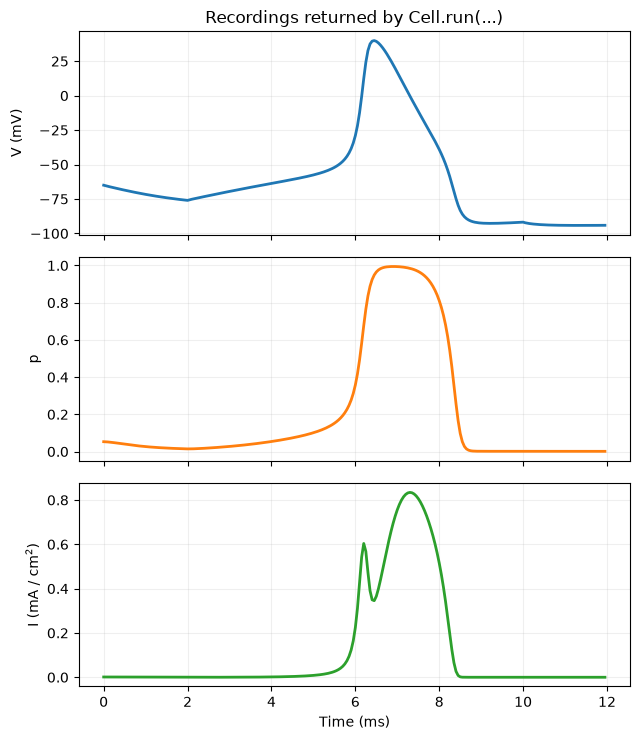

In [7]:
sim_cell = Cell(build_demo_morphology())
sim_region = BranchSlice(branch_index=[0, 1], prox=0.0, dist=1.0)

sim_cell.paint(
    sim_region,
    Channel("IL", g_max=0.03 * (u.mS / u.cm**2), E=-54.387 * u.mV),
    Channel("Na_HH1952", g_max=120.0 * (u.mS / u.cm**2)),
    Channel("K_HH1952", g_max=36.0 * (u.mS / u.cm**2)),
)

sim_cell.place(
    RootLocation(x=0.5),
    CurrentClamp(delay=2.0 * u.ms, durations=8.0 * u.ms, amplitudes=0.2 * u.nA),
)
soma = sim_cell.loc(at("soma", 0.5))
soma.record("v", braincell.observe.state("V"))
soma.record("na_p", braincell.observe.channel(name="Na_HH1952").state("p"))
soma.record("na_current", braincell.observe.channel(name="Na_HH1952").current())

result = sim_cell.run(dt=0.05 * u.ms, duration=12.0 * u.ms)

print("trace keys:", sorted(result.traces))
print("n timesteps:", int(result.time.shape[0]))
print("current time after run (ms):", float(sim_cell.current_time.to_decimal(u.ms)))

fig, axes = plt.subplots(3, 1, figsize=(6.5, 7.5), sharex=True)

times_ms = result.samples["v"].time.to_decimal(u.ms)
axes[0].plot(times_ms, result.traces["v"][:, 0].to_decimal(u.mV), color="#1f77b4", linewidth=2.0)
axes[0].set_ylabel("V (mV)")
axes[0].set_title("Recordings returned by Cell.run(...)")
axes[0].grid(True, alpha=0.2)

axes[1].plot(times_ms, result.traces["na_p"][:, 0], color="#ff7f0e", linewidth=2.0)
axes[1].set_ylabel("p")
axes[1].grid(True, alpha=0.2)

axes[2].plot(
    times_ms,
    result.traces["na_current"][:, 0].to_decimal(u.mA / u.cm**2),
    color="#2ca02c",
    linewidth=2.0,
)
axes[2].set_xlabel("Time (ms)")
axes[2].set_ylabel("I (mA / cm$^2$)")
axes[2].grid(True, alpha=0.2)

plt.tight_layout()
plt.show()

## Summary

The mechanism surface in the current multi-compartment stack is still small, and recordings read it back out:

- `CableProperty`, `Ion`, and `Channel` create the runtime objects that recordings later observe.
- Clamps, synapses, and junctions are point mechanisms, placed with `cell.place(locset, ...)`.
- A recording pairs a scope (`cell`, `cell.loc(locset)`, `cell.on(region)`, ...) with an observable: `observe.state("V")` for the voltage, and `observe.channel/ion/synapse(name=...)` with `.state(field)` or `.current()` for mechanisms.
- `observe.ion(...)` selects only ions painted with `Ion(...)`; an ion owner's `.current()` is the total over its channels.
- `cell.run(...)` returns every recording by name in `RunResult.traces` and `RunResult.samples`. Row `k` is the state at `result.time[k]`, so row 0 is the initialized state and a single-step run is a snapshot.

For more declaration detail, continue with `6.channel.ipynb` and `7.ion.ipynb`. For more locset detail, continue with `2.filter.ipynb`. For the full recording vocabulary, see `examples/cell/recording.ipynb`.